In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

In [2]:
# Load CSV files
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

# Separate features and labels
x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

# Display shapes
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (27455, 784)
Training labels: (27455,)
Testing images: (7172, 784)
Testing labels: (7172,)


In [3]:
# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Training data normalized")
print("Testing data normalized")

Training data normalized
Testing data normalized


In [4]:
# Define FNN architecture
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(26, activation="softmax")
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 26)                  │           1,690 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,426 (431.35 KB)

 Trainable params: 110,426 (431.35 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 31s 26ms/step - accuracy: 0.3385 - loss: 2.1523 - val_accuracy: 0.5390 - val_loss: 1.4251
Epoch 2/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.6030 - loss: 1.2184 - val_accuracy: 0.6730 - val_loss: 0.9843
Epoch 3/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.7153 - loss: 0.8753 - val_accuracy: 0.7327 - val_loss: 0.7646
Epoch 4/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.7902 - loss: 0.6608 - val_accuracy: 0.8219 - val_loss: 0.5540
Epoch 5/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - accuracy: 0.8415 - loss: 0.5055 - val_accuracy: 0.8467 - val_loss: 0.4686
Epoch 6/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.8868 - loss: 0.3708 - val_accuracy: 0.9042 - val_loss: 0.3204
Epoch 7/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.9165 - loss: 0.2846 - val_accuracy: 0.9377 - val_loss: 0.2198
Epoch 8/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.9343 - loss: 0.2223 - 

In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7691 - loss: 1.0723
Test Loss: 1.0722856521606445
Test Accuracy: 0.7691020369529724
Test Accuracy (%): 76.91020369529724


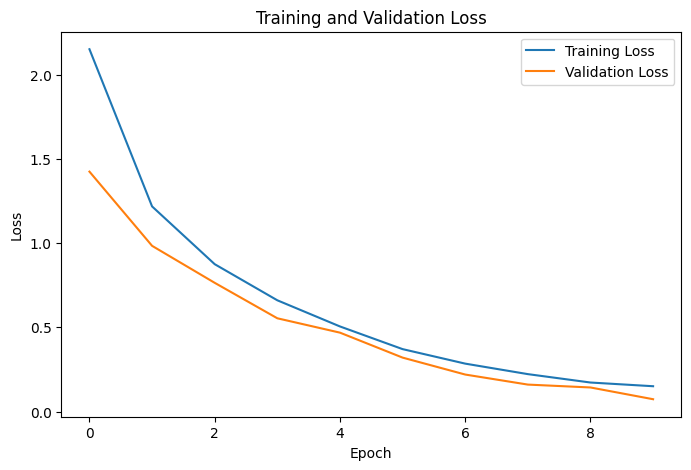

In [8]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

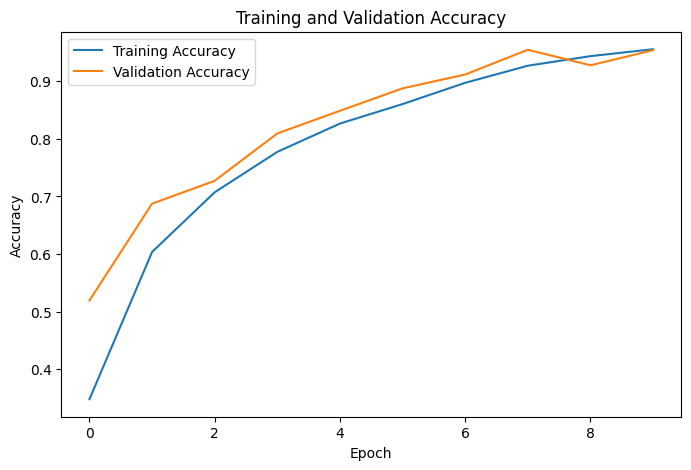

In [10]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()